# FFT -- Full Fine-Tuning baseline
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 5 / 10 / 50 / 100% | 5 seeds.

The reference every PEFT method is compared against. Each result is appended to `results.csv` the moment it finishes.

In [ ]:
!pip install -q transformers==4.57.6 peft==0.18.1, datasets==5.0.1, accelerate==1.14.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 48.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Mounted at /content/drive
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10, 5]


### Check data and progress

In [ ]:
validate_data_sizes()
print()
print_status()

 size_%                                folder  rows  actual_%_of_full  hoax_%
      5  /content/drive/MyDrive/thesis/data/5   424               5.0    50.0
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  5    10   50   100
method                       
BitFit       0    5    5    5
FFT          0    5    5    5
Houlsby      0    5    5    5
IA3          0    5    5    5
LoRA         0    5    5    5
Pfeiffer     0    5    5    5
Total: 90 / 120 for methods present


### Model definition
All parameters trainable.

In [4]:
def build_fft_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )

### Run all data sizes and seeds

In [ ]:
METHOD_NAME = "FFT"
LEARNING_RATE = 2e-5
TAG = "main"     
RUN_SIZES = DATA_SIZES 
RUN_SEEDS = SEEDS

In [6]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_fft_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)

[skip] FFT data=100% seed=42 tag=main already logged
[skip] FFT data=100% seed=123 tag=main already logged
[skip] FFT data=100% seed=456 tag=main already logged
[skip] FFT data=100% seed=789 tag=main already logged
[skip] FFT data=100% seed=2026 tag=main already logged
[skip] FFT data=50% seed=42 tag=main already logged
[skip] FFT data=50% seed=123 tag=main already logged
[skip] FFT data=50% seed=456 tag=main already logged
[skip] FFT data=50% seed=789 tag=main already logged
[skip] FFT data=50% seed=2026 tag=main already logged
[skip] FFT data=10% seed=42 tag=main already logged
[skip] FFT data=10% seed=123 tag=main already logged
[skip] FFT data=10% seed=456 tag=main already logged
[skip] FFT data=10% seed=789 tag=main already logged
[skip] FFT data=10% seed=2026 tag=main already logged

  FFT | data 5% | seed 42 | tag main | lr 2e-05


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (38 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable parameters: 124,442,882 / 124,442,882 (100.0000%)


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
531,0.050200,1.068382,0.858086,0.858148,0.858086,0.858080
1062,0.000000,1.190940,0.858086,0.858101,0.858086,0.858084
1593,0.000000,1.268629,0.858086,0.858090,0.858086,0.858085
2124,0.000000,1.330372,0.858086,0.858090,0.858086,0.858085



TEST -- Acc 0.8545 | F1 0.8545 | val F1 0.8581 | VRAM 2.024 GB | 7.8 min | 2124 steps (4 evals, best @ step 1593)

Completed seeds per (method, data size); target = 5; tag='main'
data_size  5    10   50   100
method                       
BitFit       0    5    5    5
FFT          5    5    5    5
Houlsby      0    5    5    5
IA3          0    5    5    5
LoRA         0    5    5    5
Pfeiffer     0    5    5    5
Total: 95 / 120 for methods present


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

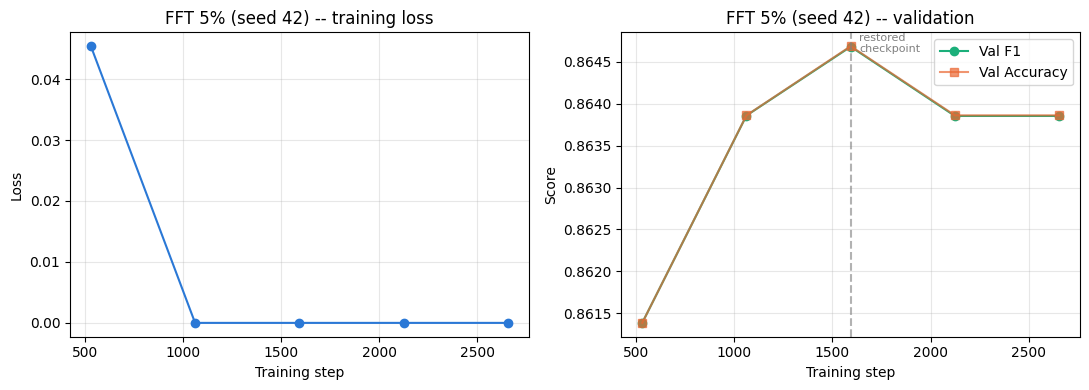

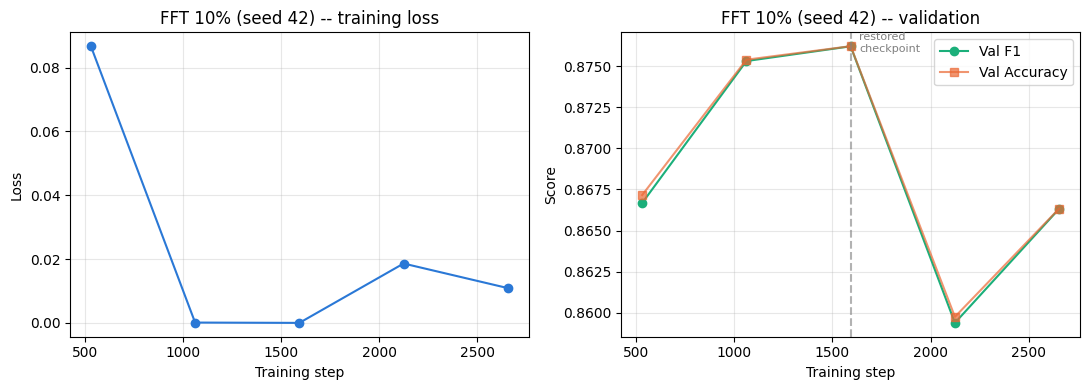

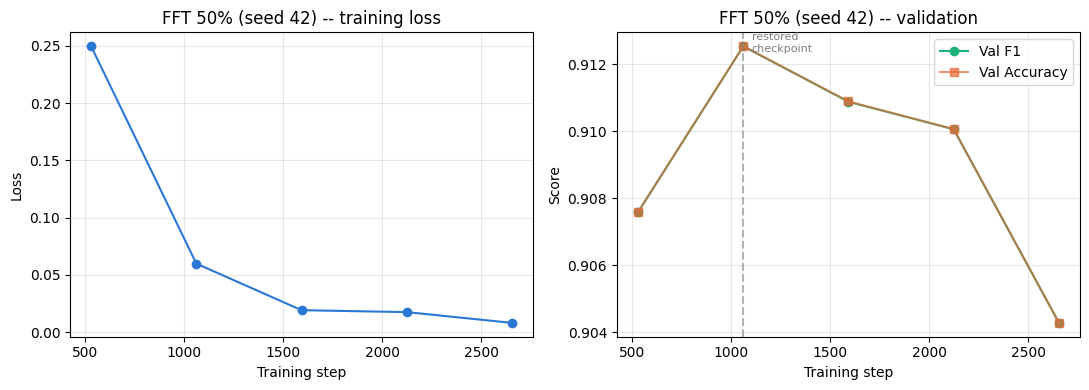

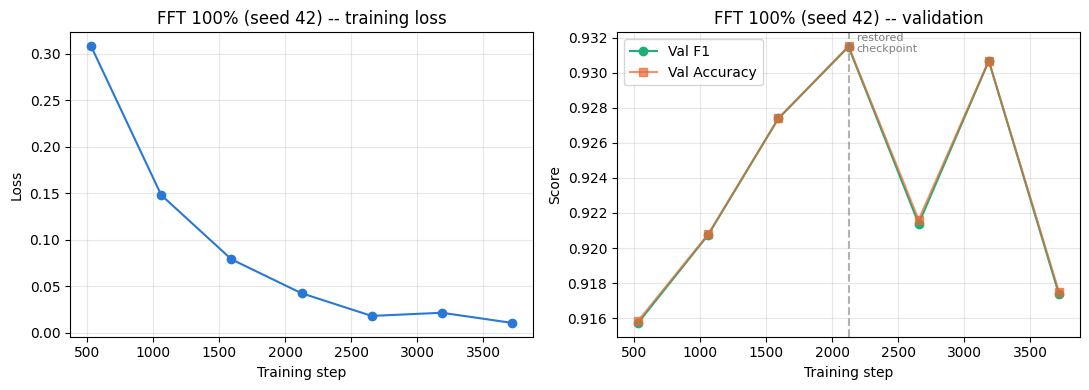

In [7]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

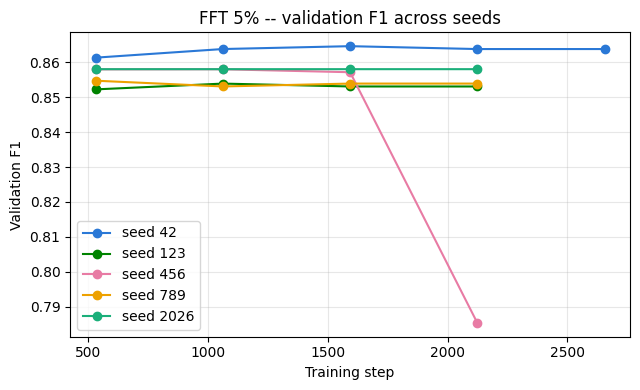

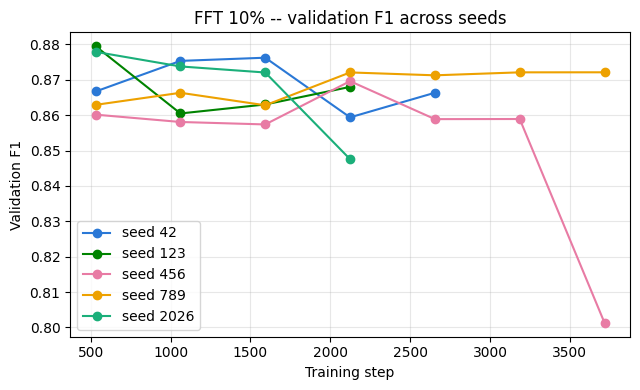

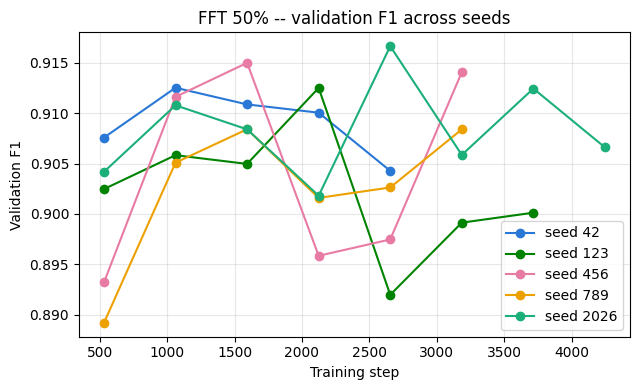

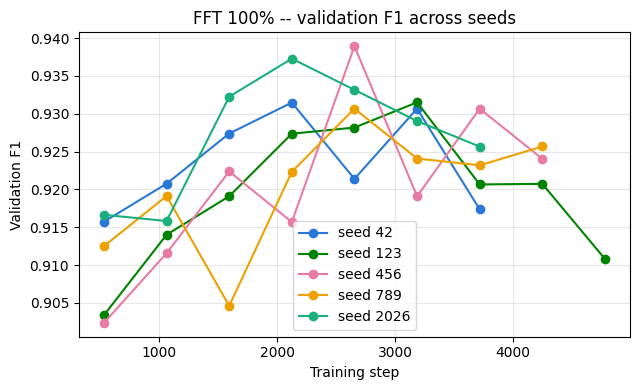

In [8]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

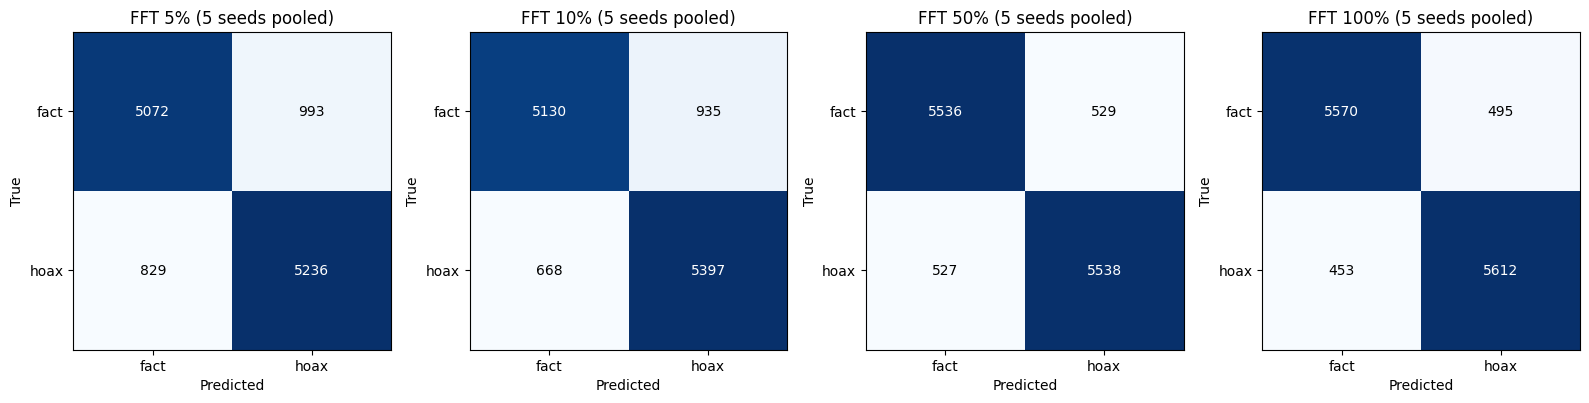

In [9]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

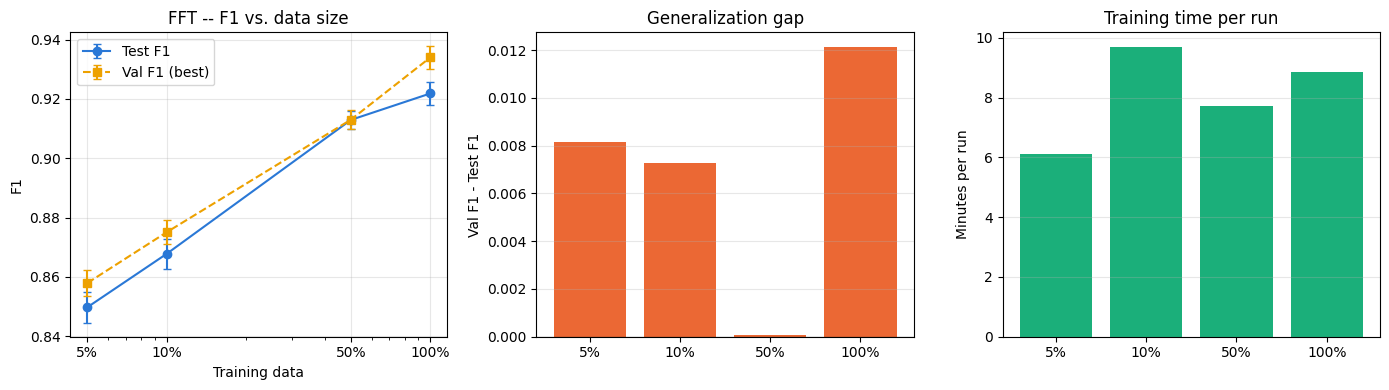

 data_size  seed  best_val_f1  accuracy       f1  trainable_pct  peak_vram_gb  total_time_s  epochs_run  steps_run
         5    42       0.8647  0.847073 0.847034          100.0         2.019         332.9           5       2655
         5   123       0.8539  0.847073 0.847068          100.0         2.020         265.3           4       2124
         5   456       0.8581  0.844188 0.844027          100.0         2.020         351.4           4       2124
         5   789       0.8548  0.856142 0.856136          100.0         2.021         419.3           4       2124
         5  2026       0.8581  0.854493 0.854486          100.0         2.024         466.2           4       2124
        10    42       0.8762  0.866447 0.866414          100.0         2.020         508.6           5       2655
        10   123       0.8795  0.863561 0.863394          100.0         2.023         475.9           4       2124
        10   456       0.8696  0.863974 0.863873          100.0         2.024   

In [10]:
plot_method_summary(METHOD_NAME, tag=TAG)